<a href="https://colab.research.google.com/github/ayulestari-ssd24/UTS-PMML/blob/main/2404220005_UTS_Prediksi_Modern_dan_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ULANGAN TENGAH SEMESTER 5             
PREDIKSI MODERN & MACHINE LEARNING

Eksperimen dan Evaluasi Model Machine Learning untuk Prediksi Default Pembayaran Kartu Kredit



Nama          : Ayu Lestari              
NIM           : 2404220005              
Program Studi : Statistika dan Sains Data                    

Install Library

In [1]:
!pip -q install xgboost

Import Library & Load Data

In [2]:
# Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

RANDOM_STATE = 42

In [3]:
# Load dataset
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("UCI_Credit_Card.csv")

df.head()

Saving UCI_Credit_Card.csv to UCI_Credit_Card.csv


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## Data Understanding & Preparation

In [4]:
# Dimensi, struktur, tipe data
print("Dimensi dataset:", df.shape)
print("\nInfo dataset:")
df.info()
print("\nStatistik deskriptif:")
display(df.describe().T)

Dimensi dataset: (30000, 25)

Info dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [5]:
# Variabel target, missing value, duplicate
TARGET = "default.payment.next.month"
print("Variabel target:", TARGET)

print("\nMissing value per kolom:")
print(df.isnull().sum())
print("Total missing value:", df.isnull().sum().sum())

print("\nDuplikat (semua kolom termasuk ID):", df.duplicated().sum())
print("Duplikat (tanpa kolom ID)        :", df.drop(columns="ID").duplicated().sum())

Variabel target: default.payment.next.month

Missing value per kolom:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64
Total missing value: 0

Duplikat (semua kolom termasuk ID): 0
Duplikat (tanpa kolom ID)        : 35


In [6]:
# Pemeriksaan nilai tidak wajar
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\nDistribusi {col}:")
    print(df[col].value_counts().sort_index())

pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
print("\nNilai unik PAY_x:")
for c in pay_cols:
    print(c, sorted(df[c].unique()))

print("\nRentang AGE :", df["AGE"].min(), "-", df["AGE"].max())
print("Rentang LIMIT_BAL:", df["LIMIT_BAL"].min(), "-", df["LIMIT_BAL"].max())
print("Jumlah BILL_AMT negatif:", (df[[f"BILL_AMT{i}" for i in range(1, 7)]] < 0).sum().sum())


Distribusi SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

Distribusi EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Distribusi MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Nilai unik PAY_x:
PAY_0 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Proporsi (%):
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


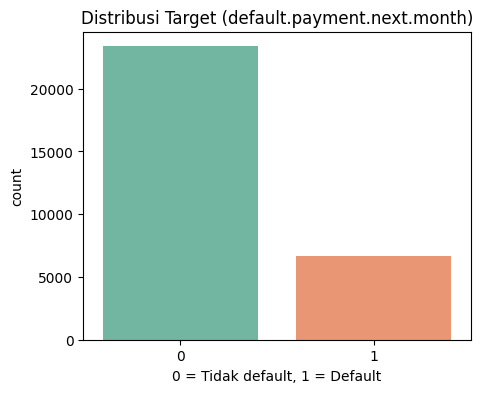

In [7]:
# Distribusi target
print(df[TARGET].value_counts())
print("\nProporsi (%):")
print(df[TARGET].value_counts(normalize=True) * 100)

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, palette="Set2")
plt.title("Distribusi Target (default.payment.next.month)")
plt.xlabel("0 = Tidak default, 1 = Default")
plt.show()

In [8]:
# Data cleaning
df_clean = df.copy()

# 1) Hapus duplikat
before = df_clean.shape[0]
df_clean = df_clean.drop(columns="ID")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Baris dihapus karena duplikat: {before - df_clean.shape[0]}")

# 2) EDUCATION: nilai 0, 5, 6 tidak terdokumentasi -> gabung ke kategori 4 (others)
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})

# 3) MARRIAGE: nilai 0 tidak terdokumentasi -> gabung ke kategori 3 (others)
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})

# 4) Samakan nama kolom PAY_0 -> PAY_1 agar konsisten dengan PAY_2..PAY_6
df_clean = df_clean.rename(columns={"PAY_0": "PAY_1"})

print("Dimensi setelah cleaning:", df_clean.shape)
print(df_clean["EDUCATION"].value_counts().sort_index())
print(df_clean["MARRIAGE"].value_counts().sort_index())

Baris dihapus karena duplikat: 35
Dimensi setelah cleaning: (29965, 24)
EDUCATION
1    10563
2    14019
3     4915
4      468
Name: count, dtype: int64
MARRIAGE
1    13643
2    15945
3      377
Name: count, dtype: int64


In [9]:
# Tentukan predictor & target, train-test split
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nProporsi target train:\n", y_train.value_counts(normalize=True))
print("\nProporsi target test:\n", y_test.value_counts(normalize=True))

X_train: (23972, 23) | X_test: (5993, 23)

Proporsi target train:
 default.payment.next.month
0    0.778742
1    0.221258
Name: proportion, dtype: float64

Proporsi target test:
 default.payment.next.month
0    0.778742
1    0.221258
Name: proportion, dtype: float64


In [10]:
# Definisi kolom & fungsi evaluasi
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]
print("Kolom kategorik:", cat_cols)
print("Kolom numerik  :", num_cols)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []   # menyimpan semua hasil eksperimen

def evaluate_model(exp, name, model, X_tr, y_tr, X_te, y_te, store=True):
    """5-fold CV (F1) pada train + evaluasi pada test set."""
    cv_f1 = cross_val_score(model, X_tr, y_tr, cv=skf, scoring="f1", n_jobs=-1)
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    res = {
        "Experiment": exp,
        "Model": name,
        "CV F1": cv_f1.mean(),
        "CV F1 Std": cv_f1.std(),
        "Test Accuracy": accuracy_score(y_te, y_pred),
        "Test Precision": precision_score(y_te, y_pred, zero_division=0),
        "Test Recall": recall_score(y_te, y_pred),
        "Test F1": f1_score(y_te, y_pred),
    }
    if store:
        results.append(res)
    return res

def show(res):
    display(pd.DataFrame([res]).round(4))

Kolom kategorik: ['SEX', 'EDUCATION', 'MARRIAGE']
Kolom numerik  : ['LIMIT_BAL', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


## Experiment 1 — Baseline Model

In [11]:
# Baseline Logistic Regression
baseline_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

res_exp1 = evaluate_model("1", "Logistic Regression (Baseline)", baseline_lr,
                          X_train, y_train, X_test, y_test)
show(res_exp1)

y_pred = baseline_lr.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

,Experiment,Model,CV F1,CV F1 Std,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Logistic Regression (Baseline),0.2695,0.0767,0.8079,0.6611,0.2707,0.3842


              precision    recall  f1-score   support

           0     0.8226    0.9606    0.8862      4667
           1     0.6611    0.2707    0.3842      1326

    accuracy                         0.8079      5993
   macro avg     0.7419    0.6157    0.6352      5993
weighted avg     0.7869    0.8079    0.7751      5993

Confusion matrix:
 [[4483  184]
 [ 967  359]]


## Experiment 2 — Preprocessing

In [12]:
# Preprocessing: StandardScaler + OneHotEncoder
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])

# a. Scaling + Encoding
lr_prep = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
res_2a = evaluate_model("2a", "LR + Scaling + OHE", lr_prep,
                        X_train, y_train, X_test, y_test)

# b. Scaling + Encoding + class_weight='balanced' (menangani ketidakseimbangan kelas)
lr_prep_bal = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])
res_2b = evaluate_model("2b", "LR + Scaling + OHE + Balanced", lr_prep_bal,
                        X_train, y_train, X_test, y_test)

pd.DataFrame([res_exp1, res_2a, res_2b]).round(4)

,Experiment,Model,CV F1,CV F1 Std,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Logistic Regression (Baseline),0.2695,0.0767,0.8079,0.6611,0.2707,0.3842
1,2a,LR + Scaling + OHE,0.3576,0.0112,0.8136,0.7267,0.2526,0.3749
2,2b,LR + Scaling + OHE + Balanced,0.4778,0.0108,0.6828,0.3723,0.6320,0.4685


In [13]:
# Pilih konfigurasi preprocessing terbaik berdasarkan CV F1
cands = {"2a": res_2a, "2b": res_2b}
best_key = max(cands, key=lambda k: cands[k]["CV F1"])
USE_BALANCED = (best_key == "2b")
print("Konfigurasi Experiment 2 terbaik:", best_key, "| class_weight balanced:", USE_BALANCED)

# Hanya konfigurasi terbaik yang dimasukkan ke tabel ringkasan akhir sebagai Experiment 2
results[:] = [r for r in results if r["Experiment"] in ["1", best_key]]
for r in results:
    if r["Experiment"] == best_key:
        r["Experiment"] = "2"

# Perbandingan dengan baseline
comp = pd.DataFrame([res_exp1, cands[best_key]])
comp["Experiment"] = ["1 (Baseline)", "2 (Preprocessing)"]
display(comp.round(4))

print("\nSelisih (Exp2 - Exp1):")
for m in ["CV F1", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]:
    print(f"{m:15s}: {cands[best_key][m] - res_exp1[m]:+.4f}")

Konfigurasi Experiment 2 terbaik: 2b | class_weight balanced: True


,Experiment,Model,CV F1,CV F1 Std,Test Accuracy,Test Precision,Test Recall,Test F1
0,1 (Baseline),Logistic Regression (Baseline),0.2695,0.0767,0.8079,0.6611,0.2707,0.3842
1,2 (Preprocessing),LR + Scaling + OHE + Balanced,0.4778,0.0108,0.6828,0.3723,0.6320,0.4685



Selisih (Exp2 - Exp1):
CV F1          : +0.2084
Test Accuracy  : -0.1251
Test Precision : -0.2889
Test Recall    : +0.3612
Test F1        : +0.0844


## Experiment 3 — Model Comparison

In [14]:
# Membandingkan LR, Decision Tree, Random Forest
cw = "balanced" if USE_BALANCED else None

models_exp3 = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight=cw,
                                            random_state=RANDOM_STATE, n_jobs=-1),
}

exp3_results = []
fitted_exp3 = {}
for name, mdl in models_exp3.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", mdl)])
    r = evaluate_model("3", name, pipe, X_train, y_train, X_test, y_test, store=False)
    exp3_results.append(r)
    fitted_exp3[name] = pipe

exp3_df = pd.DataFrame(exp3_results).set_index("Model")
display(exp3_df.drop(columns="Experiment").round(4))

,CV F1,CV F1 Std,Test Accuracy,Test Precision,Test Recall,Test F1
Model,,,,,,
Logistic Regression,0.4778,0.0108,0.6828,0.3723,0.6320,0.4685
Decision Tree,0.3896,0.0172,0.7258,0.3827,0.3899,0.3863
Random Forest,0.4466,0.0098,0.8119,0.6487,0.3273,0.4351


Model terbaik Experiment 3 (CV F1 tertinggi): Logistic Regression
Experiment               3
CV F1             0.477824
CV F1 Std         0.010836
Test Accuracy     0.682797
Test Precision    0.372279
Test Recall       0.631976
Test F1           0.468549
Name: Logistic Regression, dtype: object


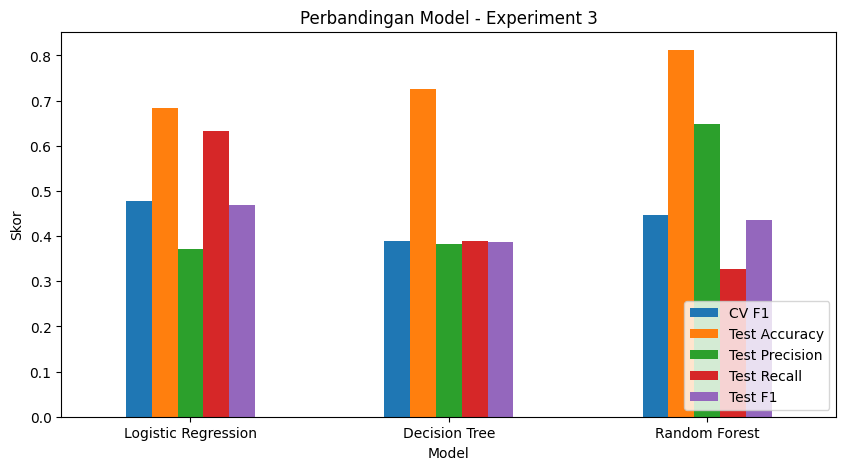

In [15]:
# Tentukan model terbaik Exp 3 (berdasarkan CV F1)
best_model_name = exp3_df["CV F1"].idxmax()
print("Model terbaik Experiment 3 (CV F1 tertinggi):", best_model_name)
print(exp3_df.loc[best_model_name].round(4))

# Simpan ke tabel ringkasan
best_row = exp3_df.loc[best_model_name].to_dict()
best_row.update({"Experiment": "3", "Model": f"Model Comparison - Best: {best_model_name}"})
results.append(best_row)

# Visualisasi perbandingan
exp3_df[["CV F1", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
plt.title("Perbandingan Model - Experiment 3")
plt.ylabel("Skor")
plt.legend(loc="lower right")
plt.show()

## Experiment 4 — Hyperparameter Tuning

In [16]:
# Grid hyperparameter untuk tiap model
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__penalty": ["l2"],
        "model__solver": ["lbfgs", "liblinear"],
        "model__class_weight": [None, "balanced"],
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_split": [2, 10, 50],
        "model__min_samples_leaf": [1, 5, 20],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 5],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"],
    },
}

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

print("Model yang di-tuning:", best_model_name)
print("Hyperparameter yang diuji:")
for k, v in param_grids[best_model_name].items():
    print(f"  {k}: {v}")

Model yang di-tuning: Logistic Regression
Hyperparameter yang diuji:
  model__C: [0.01, 0.1, 1, 10, 100]
  model__penalty: ['l2']
  model__solver: ['lbfgs', 'liblinear']
  model__class_weight: [None, 'balanced']


In [17]:
# Menjalankan GridSearchCV
pipe_tune = Pipeline([("prep", make_preprocessor()), ("model", base_models[best_model_name])])

grid = GridSearchCV(
    estimator=pipe_tune,
    param_grid=param_grids[best_model_name],
    scoring="f1",
    cv=skf,                # 5-fold CV
    n_jobs=-1,
    verbose=1,
    refit=True
)
grid.fit(X_train, y_train)

print("Kombinasi hyperparameter terbaik:", grid.best_params_)
print("Best CV F1-score:", round(grid.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Kombinasi hyperparameter terbaik: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best CV F1-score: 0.4797


In [18]:
# Evaluasi model tuned & perbandingan sebelum vs sesudah
tuned_model = grid.best_estimator_
y_pred_t = tuned_model.predict(X_test)

res_tuned = {
    "Experiment": "4",
    "Model": f"Tuned {best_model_name}",
    "CV F1": grid.best_score_,
    "CV F1 Std": grid.cv_results_["std_test_score"][grid.best_index_],
    "Test Accuracy": accuracy_score(y_test, y_pred_t),
    "Test Precision": precision_score(y_test, y_pred_t, zero_division=0),
    "Test Recall": recall_score(y_test, y_pred_t),
    "Test F1": f1_score(y_test, y_pred_t),
}
results.append(res_tuned)

before = exp3_df.loc[best_model_name].to_dict()
before.update({"Experiment": "Sebelum tuning", "Model": best_model_name})
after = dict(res_tuned); after["Experiment"] = "Setelah tuning"

cols = ["Experiment", "Model", "CV F1", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
comp4 = pd.DataFrame([before, after])[cols]
display(comp4.round(4))

print("Selisih (Setelah - Sebelum):")
for m in ["CV F1", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]:
    print(f"{m:15s}: {after[m] - before[m]:+.4f}")

print("\nClassification report (tuned):")
print(classification_report(y_test, y_pred_t, digits=4))

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Sebelum tuning,Logistic Regression,0.4778,0.6828,0.3723,0.6320,0.4685
1,Setelah tuning,Tuned Logistic Regression,0.4797,0.6878,0.3774,0.6327,0.4728


Selisih (Setelah - Sebelum):
CV F1          : +0.0018
Test Accuracy  : +0.0050
Test Precision : +0.0051
Test Recall    : +0.0008
Test F1        : +0.0043

Classification report (tuned):
              precision    recall  f1-score   support

           0     0.8708    0.7034    0.7782      4667
           1     0.3774    0.6327    0.4728      1326

    accuracy                         0.6878      5993
   macro avg     0.6241    0.6681    0.6255      5993
weighted avg     0.7617    0.6878    0.7107      5993



In [19]:
# 10 kombinasi teratas hasil grid
cv_res = pd.DataFrame(grid.cv_results_)
top = cv_res.sort_values("rank_test_score").head(10)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
display(top)

,params,mean_test_score,std_test_score,rank_test_score
2,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.479663,0.008749,1
3,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.479437,0.008917,2
7,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.478983,0.010829,3
6,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.478857,0.011225,4
11,"{'model__C': 1, 'model__class_weight': 'balanc...",0.478123,0.010568,5
15,"{'model__C': 10, 'model__class_weight': 'balan...",0.477916,0.010588,6
19,"{'model__C': 100, 'model__class_weight': 'bala...",0.477916,0.010588,6
10,"{'model__C': 1, 'model__class_weight': 'balanc...",0.477824,0.010836,8
14,"{'model__C': 10, 'model__class_weight': 'balan...",0.477818,0.010745,9
18,"{'model__C': 100, 'model__class_weight': 'bala...",0.477791,0.010658,10


## Experiment 5 — Advanced Model

In [20]:
# Gradient Boosting, AdaBoost, XGBoost
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos    # untuk menangani imbalance pada XGBoost

advanced_models = {
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=spw if USE_BALANCED else 1,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
    ),
}

exp5_results = []
for name, mdl in advanced_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", mdl)])
    r = evaluate_model("5", name, pipe, X_train, y_train, X_test, y_test, store=False)
    exp5_results.append(r)

exp5_df = pd.DataFrame(exp5_results).set_index("Model")
display(exp5_df.drop(columns="Experiment").round(4))

,CV F1,CV F1 Std,Test Accuracy,Test Precision,Test Recall,Test F1
Model,,,,,,
Gradient Boosting,0.4776,0.0190,0.8183,0.6634,0.3627,0.4690
AdaBoost,0.4472,0.0121,0.8153,0.6741,0.3198,0.4338
XGBoost,0.5409,0.0120,0.7550,0.4604,0.6222,0.5292


In [21]:
# Pilih advanced model terbaik & bandingkan dengan Experiment 4
best_adv_name = exp5_df["CV F1"].idxmax()
print("Advanced model terbaik (CV F1):", best_adv_name)

adv_row = exp5_df.loc[best_adv_name].to_dict()
adv_row.update({"Experiment": "5", "Model": f"Advanced - {best_adv_name}"})
results.append(adv_row)

comp5 = pd.DataFrame([res_tuned, adv_row])[cols]
display(comp5.round(4))

print("Selisih (Advanced - Tuned Exp 4):")
for m in ["CV F1", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]:
    print(f"{m:15s}: {adv_row[m] - res_tuned[m]:+.4f}")

Advanced model terbaik (CV F1): XGBoost


,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,4,Tuned Logistic Regression,0.4797,0.6878,0.3774,0.6327,0.4728
1,5,Advanced - XGBoost,0.5409,0.7550,0.4604,0.6222,0.5292


Selisih (Advanced - Tuned Exp 4):
CV F1          : +0.0612
Test Accuracy  : +0.0672
Test Precision : +0.0830
Test Recall    : -0.0106
Test F1        : +0.0564


## Final Summary

In [22]:
# Tabel ringkasan seluruh eksperimen
summary = pd.DataFrame(results)[["Experiment", "Model", "CV F1", "Test Accuracy",
                                 "Test Precision", "Test Recall", "Test F1"]]
summary["Experiment"] = summary["Experiment"].astype(str)
summary = summary.sort_values("Experiment").reset_index(drop=True)
display(summary.round(4))

# Simpan
summary.round(4).to_csv("summary_experiments.csv", index=False)

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Logistic Regression (Baseline),0.2695,0.8079,0.6611,0.2707,0.3842
1,2,LR + Scaling + OHE + Balanced,0.4778,0.6828,0.3723,0.6320,0.4685
2,3,Model Comparison - Best: Logistic Regression,0.4778,0.6828,0.3723,0.6320,0.4685
3,4,Tuned Logistic Regression,0.4797,0.6878,0.3774,0.6327,0.4728
4,5,Advanced - XGBoost,0.5409,0.7550,0.4604,0.6222,0.5292


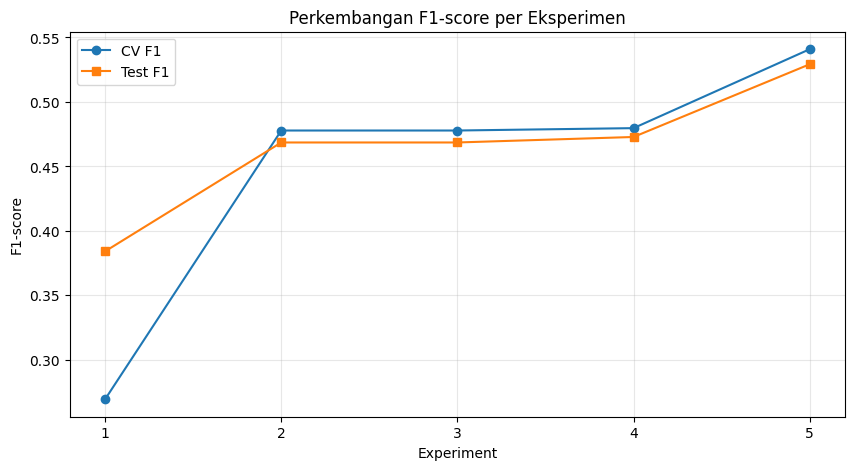

Kandidat model final (CV F1 tertinggi):
Experiment                         5
Model             Advanced - XGBoost
CV F1                       0.540855
Test Accuracy               0.755048
Test Precision              0.460379
Test Recall                 0.622172
Test F1                     0.529185
Name: 4, dtype: object


In [23]:
# Visualisasi F1 seluruh eksperimen & model final
plt.figure(figsize=(10, 5))
plt.plot(summary["Experiment"], summary["CV F1"], marker="o", label="CV F1")
plt.plot(summary["Experiment"], summary["Test F1"], marker="s", label="Test F1")
plt.title("Perkembangan F1-score per Eksperimen")
plt.xlabel("Experiment"); plt.ylabel("F1-score")
plt.grid(alpha=.3); plt.legend()
plt.show()

# Kandidat model final: Test F1 & CV F1 tertinggi
final_idx = summary["CV F1"].idxmax()
print("Kandidat model final (CV F1 tertinggi):")
print(summary.loc[final_idx])